Components for 95% variance: 123


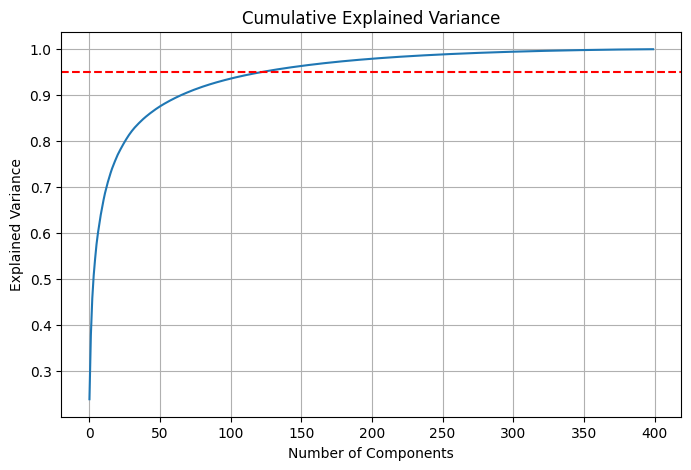

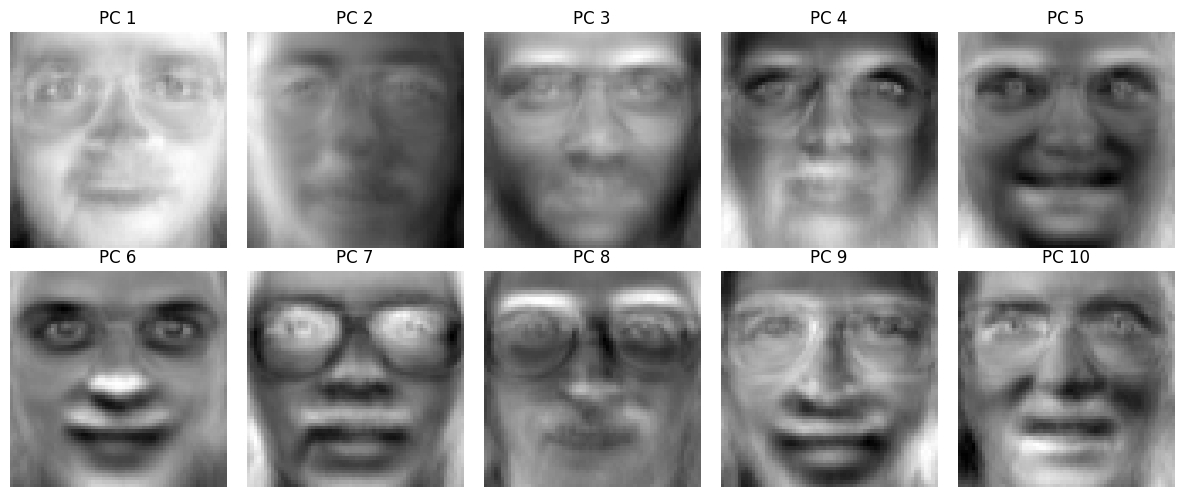

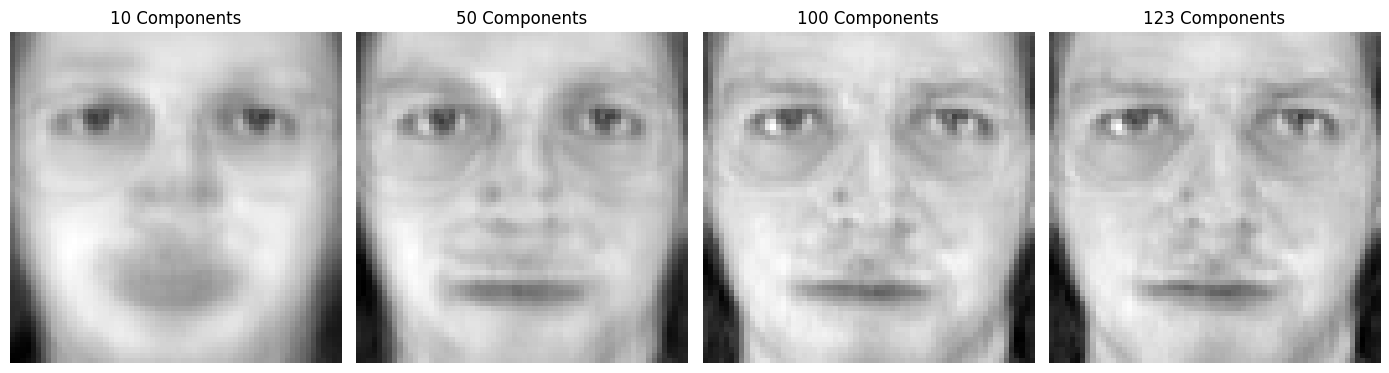

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

# Load dataset
data = fetch_olivetti_faces()
X = data.data

# Apply PCA
pca = PCA()
pca.fit(X)

# Calculate cumulative variance
cum = np.cumsum(pca.explained_variance_ratio_)

# Find components for 95% variance
k = np.argmax(cum >= 0.95) + 1

print("Components for 95% variance:", k)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(cum)
plt.axhline(0.95, color="red", linestyle="--")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Explained Variance")
plt.grid()
plt.show()

# Display first 10 principal components
fig, ax = plt.subplots(2, 5, figsize=(12, 5))

for i, a in enumerate(ax.ravel()):
    a.imshow(
        pca.components_[i].reshape(64, 64),
        cmap="gray"
    )
    a.set_title(f"PC {i+1}")
    a.axis("off")

plt.tight_layout()
plt.show()

# Reconstruct first image using different components
fig, ax = plt.subplots(1, 4, figsize=(14, 4))

image = X[:1]

for a, n in zip(ax, [10, 50, 100, k]):
    pca_model = PCA(n_components=n)
    transformed = pca_model.fit(X).transform(image)
    reconstructed = pca_model.inverse_transform(transformed)

    a.imshow(reconstructed.reshape(64, 64), cmap="gray")
    a.set_title(f"{n} Components")
    a.axis("off")

plt.tight_layout()
plt.show()